#Exp 2: Eight queens problem using Python


###Example 1: Generate and Test

In [18]:
from itertools import permutations
import time

def conflicts(board):
    """board[c] = row of the queen in column c. Count attacking pairs."""
    n = len(board)
    bad = 0

    for i in range(n):
        for j in range(i + 1, n):
            same_row = board[i] == board[j]
            same_diag = abs(board[i] - board[j]) == abs(i - j)

            if same_row or same_diag:
                bad += 1

    return bad

t0 = time.perf_counter()

sols = [p for p in permutations(range(8)) if conflicts(p) == 0]

print(f"{len(sols)} solutions in {time.perf_counter() - t0:.3f} s")
print("first:", sols[10])  # expect 92 solutions

92 solutions in 0.146 s
first: (1, 6, 4, 7, 0, 3, 5, 2)


92 solutions, 15720 nodes visited


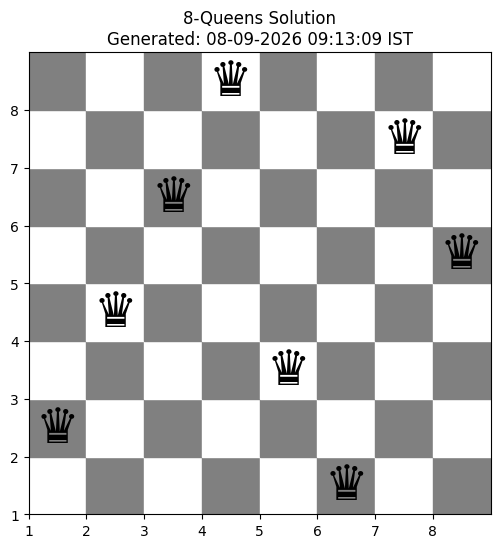

In [27]:
import matplotlib.pyplot as plt
from datetime import datetime
from zoneinfo import ZoneInfo


# Check whether a queen can be safely placed
def is_safe(board, col, row):
    for c in range(col):
        # Check same row or diagonal
        if board[c] == row or abs(board[c] - row) == abs(c - col):
            return False

    return True


# Solve N-Queens using backtracking
def solve(n):
    board = [-1] * n
    solutions = []
    nodes = 0

    def backtrack(col):
        nonlocal nodes

        # All queens have been placed
        if col == n:
            solutions.append(tuple(board))
            return

        # Try every row in the current column
        for row in range(n):
            nodes += 1

            if is_safe(board, col, row):
                board[col] = row
                backtrack(col + 1)
                board[col] = -1  # Backtrack

    backtrack(0)

    return solutions, nodes


# Draw the chessboard
def draw_board(solution):
    n = len(solution)

    # Get current date and time in Indian Standard Time
    current_datetime = datetime.now(
        ZoneInfo("Asia/Kolkata")
    ).strftime("%d-%m-%Y %H:%M:%S IST")

    # Create chessboard
    fig, ax = plt.subplots(figsize=(6, 6))

    # Draw squares
    for row in range(n):
        for col in range(n):

            color = "white" if (row + col) % 2 == 0 else "gray"

            ax.add_patch(
                plt.Rectangle(
                    (col, row),
                    1,
                    1,
                    color=color
                )
            )

    # Draw queens
    for col, row in enumerate(solution):
        ax.text(
            col + 0.5,
            row + 0.5,
            "♛",
            fontsize=35,
            ha="center",
            va="center"
        )

    # Board settings
    ax.set_xlim(0, n)
    ax.set_ylim(0, n)

    ax.set_xticks(range(n))
    ax.set_yticks(range(n))

    ax.set_xticklabels(range(1, n + 1))
    ax.set_yticklabels(range(1, n + 1))

    ax.set_aspect("equal")

    # Display title with IST date and time
    ax.set_title(
        f"{n}-Queens Solution\n"
        f"Generated: {current_datetime}"
    )

    plt.show()


# Solve the 8-Queens problem
sols, nodes = solve(8)

# Print results
print(len(sols), "solutions,", nodes, "nodes visited")

# Display the fifth solution
draw_board(sols[4])

### Example 2: Backtracking with Pruning

In [19]:
def is_safe(board, col, row):
    """Can we put a queen at (row, col) given columns 0..col-1?"""
    for c in range(col):
        if board[c] == row or abs(board[c] - row) == abs(c - col):
            return False
    return True

nodes = 0

def solve(board, col, n=8, collect=None):
    global nodes

    if col == n:                          # all columns filled: a solution
        collect.append(tuple(board))
        return

    for row in range(n):
        nodes += 1

        if is_safe(board, col, row):
            board[col] = row              # place
            solve(board, col + 1, n, collect)
            board[col] = -1               # UNDO — this is the 'back' in backtracking

found = []
solve([-1] * 8, 0, 8, found)

print(len(found), "solutions;", nodes, "nodes visited")

92 solutions; 15720 nodes visited


In [23]:
import time

print(f"{'n':>3} {'solutions':>10} {'nodes':>10} {'backtrack':>11} {'generate':>11}")

for n in range(4, 11):
    t0 = time.perf_counter();s, nd = solve(n);tb = time.perf_counter() - t0

    t0 = time.perf_counter()
    _ = [p for p in permutations(range(n)) if conflicts(p) == 0]
    tg = time.perf_counter() - t0

    print(f'{n:>3} {len(s):>10} {nd:>10} {tb:>10.4f}s {tg:>10.4f}s')

  n  solutions      nodes   backtrack    generate
  4          2         60     0.0000s     0.0000s
  5         10        220     0.0002s     0.0002s
  6          4        894     0.0004s     0.0018s
  7         40       3584     0.0019s     0.0209s
  8         92      15720     0.0096s     0.1632s
  9        352      72378     0.0298s     2.5255s
 10        724     348150     0.1964s    23.8334s
